**Objetivo do projeto**

Este projeto tem como objetivo colocar em prática meus aprendizados na minha pós-graduação em ciência de dados aplicada à saúde e desenvolver um modelo de classificação capaz de prever se um paciente é ou não diabético, com base em suas características e informações clínicas. 

**Metodologia**

O projeto envolve análise exploratória dos dados, pré-processamento das variáveis, treinamento de modelos de classificação e avaliação de desempenho.

Foram avaliadas diferentes abordagens, incluindo Regressão Logística, Regressão Logística com ajuste de pesos para lidar com o desbalanceamento das classes e Random Forest. Também foram analisados diferentes limiares de classificação (thresholds) para compreender seus efeitos sobre as previsões.

**Métricas de avaliação**

O desempenho dos modelos foi avaliado por meio de métricas como precision, recall, F1-score, ROC-AUC e PR-AUC, considerando a importância de identificar corretamente os pacientes com diabetes.

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)

In [5]:
df = pd.read_csv('diabetes_prediction_dataset.csv')

In [6]:
df.head(10)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
5,Female,20.0,0,0,never,27.32,6.6,85,0
6,Female,44.0,0,0,never,19.31,6.5,200,1
7,Female,79.0,0,0,No Info,23.86,5.7,85,0
8,Male,42.0,0,0,never,33.64,4.8,145,0
9,Female,32.0,0,0,never,27.32,5.0,100,0


In [7]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.074850,0.263150,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.039420,0.194593,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.085000,0.278883,0.00,0.00,0.00,0.00,1.00


In [9]:
df.duplicated().sum()

np.int64(3854)

In [10]:
df = df.drop_duplicates()

In [11]:
df["smoking_history"].value_counts(dropna=False)

smoking_history
never          34398
No Info        32887
former          9299
current         9197
not current     6367
ever            3998
Name: count, dtype: int64

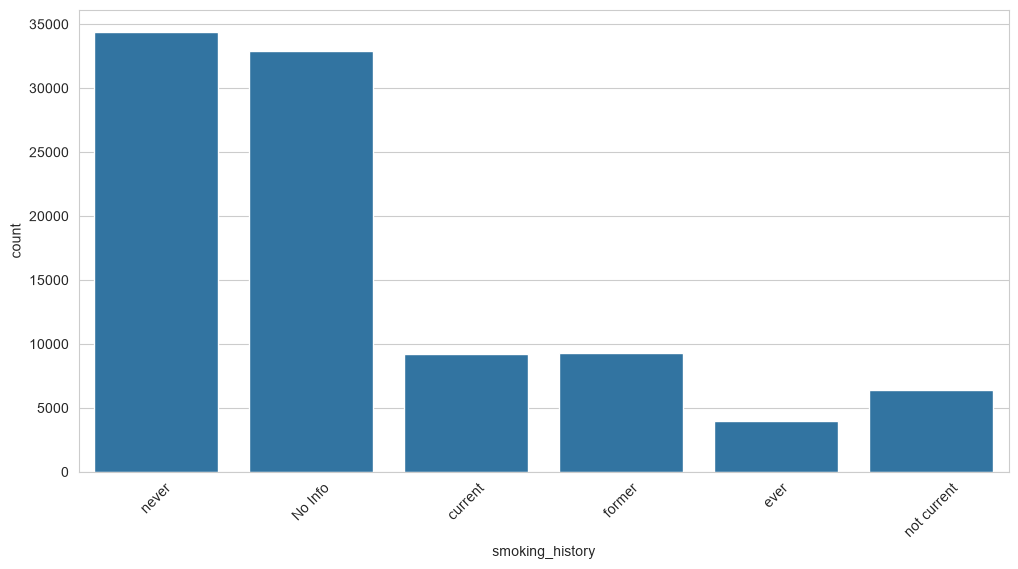

In [12]:
sns.countplot(data=df, x="smoking_history")
plt.xticks(rotation=45)
plt.show()

In [13]:
df["gender"].value_counts(dropna=False)

gender
Female    56161
Male      39967
Other        18
Name: count, dtype: int64

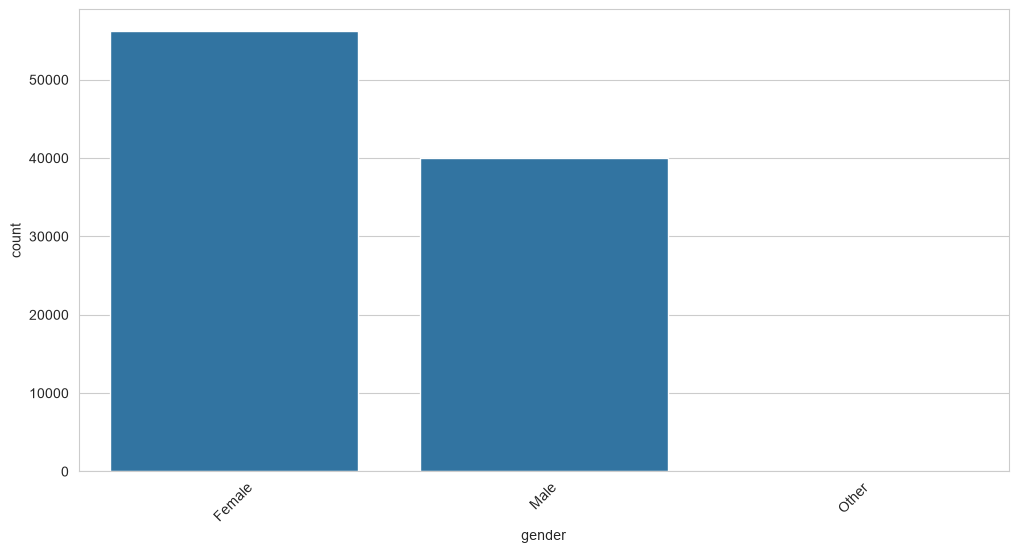

In [14]:
sns.countplot(data=df, x="gender")
plt.xticks(rotation=45)
plt.show()

In [15]:
df.describe().loc[["min", "max"]]

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
min,0.08,0.0,0.0,10.01,3.5,80.0,0.0
max,80.00,1.0,1.0,95.69,9.0,300.0,1.0


In [16]:
df["bmi"].quantile([0.01, 0.25, 0.50, 0.75, 0.99])

0.01    14.550
0.25    23.400
0.50    27.320
0.75    29.860
0.99    48.971
Name: bmi, dtype: float64

In [17]:
(df["bmi"] > 48.79).sum()

np.int64(1000)

In [18]:
df["diabetes"].value_counts()

diabetes
0    87664
1     8482
Name: count, dtype: int64

In [19]:
df.groupby("diabetes")["age"].mean()

diabetes
0    39.943229
1    60.925961
Name: age, dtype: float64

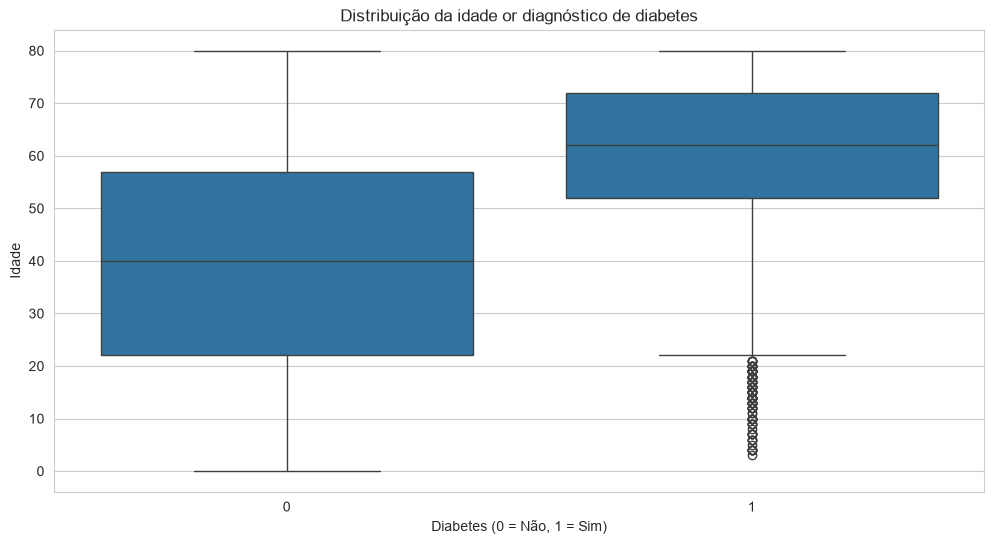

In [20]:
sns.boxplot(data=df, x="diabetes", y="age")
plt.title("Distribuição da idade or diagnóstico de diabetes")
plt.xlabel("Diabetes (0 = Não, 1 = Sim)")
plt.ylabel("Idade")
plt.show()

In [21]:
df.groupby("diabetes")["blood_glucose_level"].mean()

diabetes
0    132.818489
1    194.026173
Name: blood_glucose_level, dtype: float64

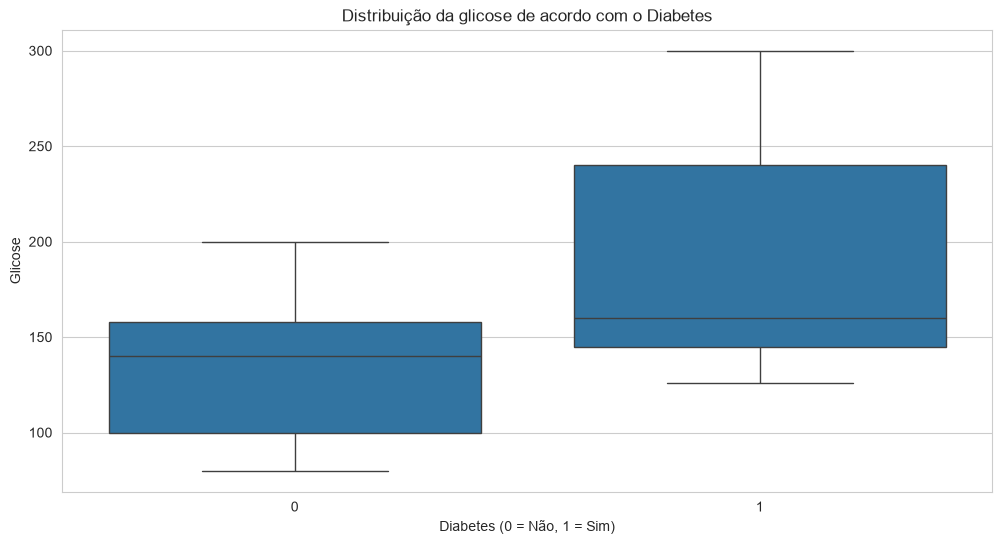

In [22]:
sns.boxplot(data=df, x="diabetes", y="blood_glucose_level")
plt.title("Distribuição da glicose de acordo com o Diabetes")
plt.xlabel("Diabetes (0 = Não, 1 = Sim)")
plt.ylabel("Glicose")
plt.show()

In [23]:
df_model = df.copy()
X = df_model.drop("diabetes",axis=1)
y = df_model["diabetes"]

In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [25]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(76916, 8)
(19230, 8)
(76916,)
(19230,)


In [35]:
col_cat = ["gender", "smoking_history"]
col_num = ["age", 
           "bmi",
           "HbA1c_level",
           "blood_glucose_level",
           "hypertension",
           "heart_disease"]

In [36]:
col_num_cont = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
col_num_bin = ["hypertension", "heart_disease"]


In [37]:
preprocessor = ColumnTransformer(transformers=[("cat", OneHotEncoder(handle_unknown="ignore"), col_cat), ("num_cont", StandardScaler(), col_num_cont),
("num_bin","passthrough", col_num_bin)]
)

In [38]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [39]:
print(X_train_processed.shape)
print(X_test_processed.shape)

(76916, 15)
(19230, 15)


In [40]:
preprocessor.get_feature_names_out()

array(['cat__gender_Female', 'cat__gender_Male', 'cat__gender_Other',
       'cat__smoking_history_No Info', 'cat__smoking_history_current',
       'cat__smoking_history_ever', 'cat__smoking_history_former',
       'cat__smoking_history_never', 'cat__smoking_history_not current',
       'num_cont__age', 'num_cont__bmi', 'num_cont__HbA1c_level',
       'num_cont__blood_glucose_level', 'num_bin__hypertension',
       'num_bin__heart_disease'], dtype=object)

In [41]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(random_state = 42)
model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [43]:
y_pred = model.predict(X_test_processed)

In [44]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[17372   162]
 [  613  1083]]


In [45]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.87      0.64      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.81      0.86     19230
weighted avg       0.96      0.96      0.96     19230



In [46]:
model_balanced = LogisticRegression(
    random_state=42,
    class_weight = "balanced"
)
model_balanced.fit(X_train_processed, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the follo

In [47]:
y_pred_balanced = model_balanced.predict(X_test_processed)

In [48]:
print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



In [49]:
confusion_matrix(y_test, y_pred_balanced)

array([[15515,  2019],
       [  204,  1492]])

In [53]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
comparacao = {
    "Modelo": ["Regressão Logística", "Regressão Logística + Balanced"],
    "Accuracy": [accuracy_score(y_test, y_pred),
                accuracy_score(y_test, y_pred_balanced)
                                ],
    "recall": [ 
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_balanced)
    ],
    "F1": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_balanced)
    ]
}
pd.DataFrame(comparacao)

,Modelo,Accuracy,recall,F1
0,Regressão Logística,0.959698,0.638561,0.736484
1,Regressão Logística + Balanced,0.884399,0.879717,0.573075


In [55]:
y_prob = model.predict_proba(X_test_processed)[:,1]
print(y_prob[:10])

[3.19763223e-01 1.20018571e-05 4.10628000e-02 2.60722598e-04
 1.16137126e-02 1.51002734e-05 6.80672420e-05 7.35859715e-03
 5.60775948e-02 6.06745576e-04]


In [56]:
threshold = 0.30
y_pred_30 = (y_prob >= threshold).astype(int)
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_30))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97     17534
           1       0.72      0.72      0.72      1696

    accuracy                           0.95     19230
   macro avg       0.85      0.85      0.85     19230
weighted avg       0.95      0.95      0.95     19230



In [65]:
thresholds = [0.5, 0.4, 0.3, 0.2]

resultados = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    resultados.append([
        threshold,
        precision_score(y_test, y_pred_threshold),
        recall_score(y_test, y_pred_threshold),
        f1_score(y_test, y_pred_threshold)
    ])

resultados_df = pd.DataFrame(
    resultados,
    columns=["Threshold", "Precision", "Recall", "F1"]
)

resultados_df

,Threshold,Precision,Recall,F1
0,0.5,0.869880,0.638561,0.736484
1,0.4,0.803824,0.669222,0.730373
2,0.3,0.721234,0.716981,0.719101
3,0.2,0.602022,0.772406,0.676653


In [66]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [67]:
rf_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [69]:
y_pred_rf = rf_model.predict(X_test_processed)

In [70]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.95      0.69      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.84      0.89     19230
weighted avg       0.97      0.97      0.97     19230



In [71]:
from sklearn.metrics import confusion_matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

[[17468    66]
 [  525  1171]]


In [75]:
from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score
)
comparacao_modelos = pd.DataFrame({
    "Modelo": [
        "Regressão Logística",
        "Regressão Logística + Balanced",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_rf)
    ],
    "F1": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_rf)
    ]
})
comparacao_modelos

,Modelo,Accuracy,Precision,Recall,F1
0,Regressão Logística,0.959698,0.869880,0.638561,0.736484
1,Regressão Logística + Balanced,0.884399,0.424950,0.879717,0.573075
2,Random Forest,0.969267,0.946645,0.690448,0.798500


In [76]:
y_pred_30 = (y_prob >= 0.30).astype(int)

comparacao_modelos_2 = pd.DataFrame({
"Modelo": [
"Regressão Logística",
"Regressão Logística + Balanced",
"Regressão Logística (threshold 0.3)",
"Random Forest"
],
"Accuracy": [
accuracy_score(y_test, y_pred),
accuracy_score(y_test, y_pred_balanced),
accuracy_score(y_test, y_pred_30),
accuracy_score(y_test, y_pred_rf)
],
"Precision": [
precision_score(y_test, y_pred),
precision_score(y_test, y_pred_balanced),
precision_score(y_test, y_pred_30),
precision_score(y_test, y_pred_rf)
],
"Recall": [
recall_score(y_test, y_pred),
recall_score(y_test, y_pred_balanced),
recall_score(y_test, y_pred_30),
recall_score(y_test, y_pred_rf)
],
"F1": [
f1_score(y_test, y_pred),
f1_score(y_test, y_pred_balanced),
f1_score(y_test, y_pred_30),
f1_score(y_test, y_pred_rf)
]
})

comparacao_modelos_2

,Modelo,Accuracy,Precision,Recall,F1
0,Regressão Logística,0.959698,0.869880,0.638561,0.736484
1,Regressão Logística + Balanced,0.884399,0.424950,0.879717,0.573075
2,Regressão Logística (threshold 0.3),0.950598,0.721234,0.716981,0.719101
3,Random Forest,0.969267,0.946645,0.690448,0.798500


In [78]:
from sklearn.metrics import roc_auc_score
auc_logistica = roc_auc_score(y_test, y_prob)
print("ROC-AUC:", auc_logistica)

ROC-AUC: 0.9598934872624829


In [79]:
y_prob = model.predict_proba(X_test_processed)[:, 1]

In [80]:
y_prob_balanced = model_balanced.predict_proba(X_test_processed)[:,1]
auc_balanced = roc_auc_score(y_test, y_prob_balanced)
print("ROC-AUC Balanced:", auc_balanced)

ROC-AUC Balanced: 0.9600669373357639


In [81]:
y_prob_rf = rf_model.predict_proba(X_test_processed)[:,1]
auc_rf = roc_auc_score(y_test, y_prob_rf)
print("ROC-AUC Random Forest:", auc_rf)

ROC-AUC Random Forest: 0.9587393111980821


In [82]:
from sklearn.metrics import average_precision_score
pr_auc_logistica = average_precision_score(y_test, y_prob)
print("PR-AUC:", pr_auc_logistica)

PR-AUC: 0.8173652026697775


In [83]:
pr_auc_balanced = average_precision_score(y_test, y_prob_balanced)
print("PR-AUC Balanced:", pr_auc_balanced)

PR-AUC Balanced: 0.8166147750432189


In [84]:
pr_auc_rf = average_precision_score(y_test, y_prob_rf)
print("PR-AUC Random Forest:", pr_auc_rf)

PR-AUC Random Forest: 0.8519926796451919


In [85]:
resultados = pd.DataFrame({
"Modelo": [
"Regressão Logística",
"Logística + Balanced",
"Logística (threshold 0.3)",
"Random Forest"
],
"Accuracy": [
0.959698,
0.884399,
0.950598,
0.969267
],
"Precision": [
0.869880,
0.424950,
0.721234,
0.946645
],
"Recall": [
0.638561,
0.879717,
0.716981,
0.690448
],
"F1": [
0.736484,
0.573075,
0.719101,
0.798500
],
"ROC-AUC": [
auc_logistica,
auc_balanced,
auc_logistica, # threshold não altera o ROC-AUC
auc_rf
],
"PR-AUC": [
pr_auc_logistica,
pr_auc_balanced,
pr_auc_logistica, # threshold não altera o PR-AUC
pr_auc_rf
]
})

resultados

,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Regressão Logística,0.959698,0.869880,0.638561,0.736484,0.959893,0.817365
1,Logística + Balanced,0.884399,0.424950,0.879717,0.573075,0.960067,0.816615
2,Logística (threshold 0.3),0.950598,0.721234,0.716981,0.719101,0.959893,0.817365
3,Random Forest,0.969267,0.946645,0.690448,0.798500,0.958739,0.851993


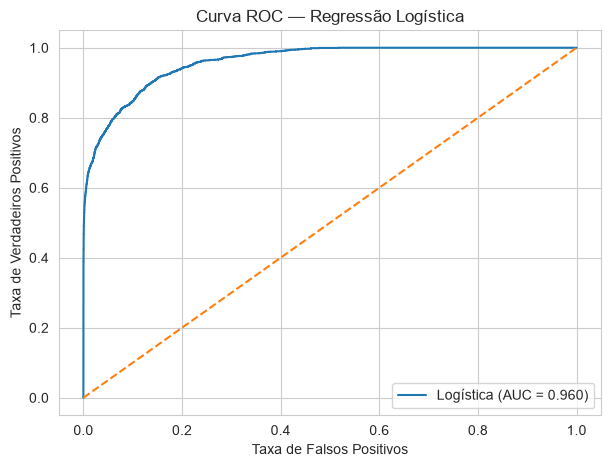

In [86]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logística (AUC = {auc_logistica:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("Taxa de Falsos Positivos")
plt.ylabel("Taxa de Verdadeiros Positivos")
plt.title("Curva ROC — Regressão Logística")
plt.legend()
plt.show()

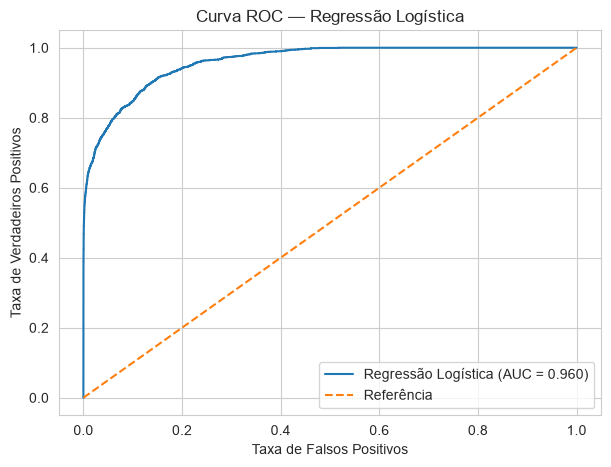

In [87]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
fpr,
tpr,
label=f"Regressão Logística (AUC = {auc_logistica:.3f})"
)

plt.plot(
[0, 1],
[0, 1],
linestyle="--",
label="Referência"
)

plt.xlabel("Taxa de Falsos Positivos")
plt.ylabel("Taxa de Verdadeiros Positivos")
plt.title("Curva ROC — Regressão Logística")
plt.legend()
plt.show()

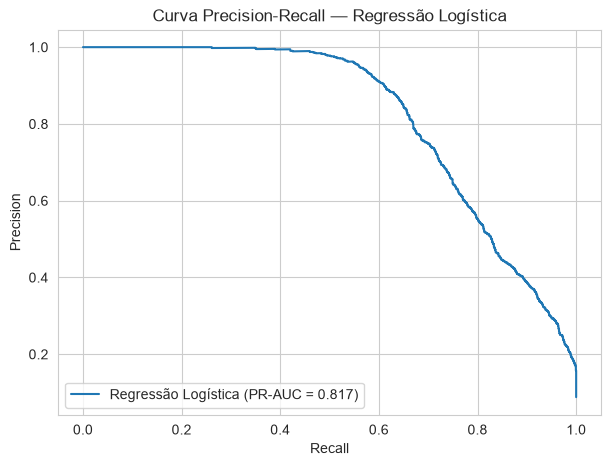

In [88]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds_pr = precision_recall_curve(
y_test,
y_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
recall,
precision,
label=f"Regressão Logística (PR-AUC = {pr_auc_logistica:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall — Regressão Logística")
plt.legend()
plt.show()

In [89]:
feature_names = preprocessor.get_feature_names_out()

importances = rf_model.feature_importances_

feature_importance = pd.DataFrame({
"feature": feature_names,
"importance": importances
})

feature_importance = feature_importance.sort_values(
"importance",
ascending=False
)

feature_importance.head(15)

,feature,importance
11,num_cont__HbA1c_level,0.395949
12,num_cont__blood_glucose_level,0.326571
10,num_cont__bmi,0.123093
9,num_cont__age,0.104923
13,num_bin__hypertension,0.015903
14,num_bin__heart_disease,0.010323
3,cat__smoking_history_No Info,0.003964
7,cat__smoking_history_never,0.003588
6,cat__smoking_history_former,0.003465
4,cat__smoking_history_current,0.002665


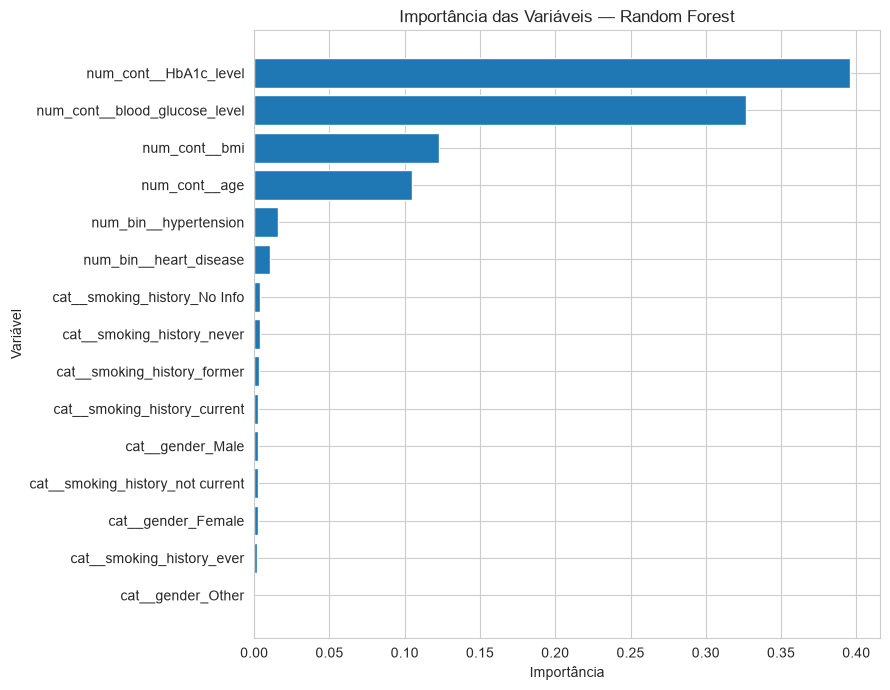

In [90]:
plt.figure(figsize=(9, 7))

plt.barh(
feature_importance["feature"].head(15)[::-1],
feature_importance["importance"].head(15)[::-1]
)

plt.xlabel("Importância")
plt.ylabel("Variável")
plt.title("Importância das Variáveis — Random Forest")

plt.tight_layout()
plt.show()

**Conclusão:** Foram avaliadas diferentes abordagens de classificação para a previsão de diabetes, considerando o desbalanceamento entre as classes. A Regressão Logística apresentou ROC-AUC de 0,960, enquanto o Random Forest apresentou ROC-AUC de 0,959 e PR-AUC de 0,852. Entre as configurações avaliadas, o Random Forest apresentou F1 de 0,799, precision de 0,947 e recall de 0,690 para a classe positiva. A análise também mostrou que alterações no balanceamento e no threshold modificam significativamente a relação entre precision e recall. Para a versão final do projeto, será utilizado o Random Forest como modelo principal, mantendo o threshold padrão de 0,5.

**Limitações:** Este projeto foi desenvolvido para fins de estudo. Portanto, os resultados não devem ser utilizados na prática clínica para diagnosticar diabetes, pois os modelos ainda precisariam de validações adicionais.